# Florida Home Values: Data Wrangling and Exploratory Analysis

This notebook prepares the Zillow Home Value Index (ZHVI) data and explores how Florida changed from January 2000 through January 2026. The broader project began as a search for undervalued U.S. housing markets. Because the available file contains only state-level home values, the final modeling question is narrower: **how accurately can recent Florida values predict the following month?**

## Questions

1. Is the data complete enough for a Florida time-series model?
2. How has Florida's typical home value changed relative to California, Texas, and New York?
3. When did Florida experience its fastest year-over-year growth?
4. What did the latest cross-state snapshot look like?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({"figure.figsize": (11, 6), "figure.dpi": 110})

DATA_PATH = Path("../data/zhvi.csv")
FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(exist_ok=True)

dollar_thousands = FuncFormatter(lambda x, _: f"${x/1000:,.0f}K")

## Load and inspect the data

In [2]:
raw = pd.read_csv(DATA_PATH)
date_column = raw.columns[0]
raw = raw.rename(columns={date_column: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"])
raw = raw.sort_values("Date").set_index("Date")

print(f"Rows: {raw.shape[0]:,}")
print(f"State and district columns: {raw.shape[1]:,}")
print(f"Date range: {raw.index.min():%B %Y} to {raw.index.max():%B %Y}")
raw.head()

Rows: 313
State and district columns: 51
Date range: January 2000 to January 2026


,Florida,California,Texas,New York,Virginia,Arizona,Massachusetts,Utah,the District of Columbia,Washington,...,North Dakota,Louisiana,Wyoming,Arkansas,Oklahoma,Kentucky,Alaska,Nebraska,Delaware,South Dakota
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-01,106839.437513,185932.000267,111831.965571,149637.593311,122778.084361,134711.717076,192670.172342,166397.340937,158963.698803,171436.108039,...,NaN,108000.701408,NaN,87413.751613,82185.060767,87953.050874,133100.235315,112888.886116,146721.635463,105043.280158
2000-02-01,107070.861680,186556.973217,111892.737950,150170.450133,123095.788877,134955.719599,193313.433955,166488.507251,159483.634688,171822.806052,...,NaN,108209.025004,NaN,87530.575926,82218.962313,87998.460603,133251.409063,113069.343667,146949.900655,104820.097891
2000-03-01,107351.393901,187400.839738,111922.213506,150683.410757,123432.630242,135269.755328,194078.813769,166631.638154,160221.370093,172217.272453,...,NaN,108370.909948,NaN,87663.122946,82376.988281,88081.081745,133402.503748,113236.594627,147234.111366,104507.770821
2000-04-01,107921.643751,189232.622338,112068.503303,151786.649610,124069.148395,135910.998187,195586.289264,166990.756067,161803.226607,173013.406497,...,NaN,108735.870458,NaN,87946.132255,82664.745283,88286.402842,133579.702498,113496.218868,147884.094822,104086.787429
2000-05-01,108536.596763,191361.793669,112163.242870,152928.107451,124683.636950,136637.856037,197218.057247,168292.216995,163558.794607,173882.336749,...,NaN,109122.542409,NaN,88225.267260,83051.247688,88559.280277,133846.461332,113627.876782,148625.429884,103911.646036


In [3]:
missing = raw.isna().sum().sort_values(ascending=False)
print("Columns with missing values:", int((missing > 0).sum()))
print("Missing Florida values:", int(raw["Florida"].isna().sum()))
missing.head(10).to_frame("missing_months")

Columns with missing values: 9
Missing Florida values: 0


,missing_months
North Dakota,108
Montana,61
New Mexico,27
Wyoming,27
South Dakota,1
West Virginia,1
Idaho,1
Alaska,1
Arizona,1
Tennessee,0


Florida has a complete monthly series, so the model does not need imputation. Some other states begin later. I keep their missing values for the overview and use only available values in each cross-state calculation. This avoids dropping valid Florida history because another state is missing an early observation.

## Florida and three comparison states

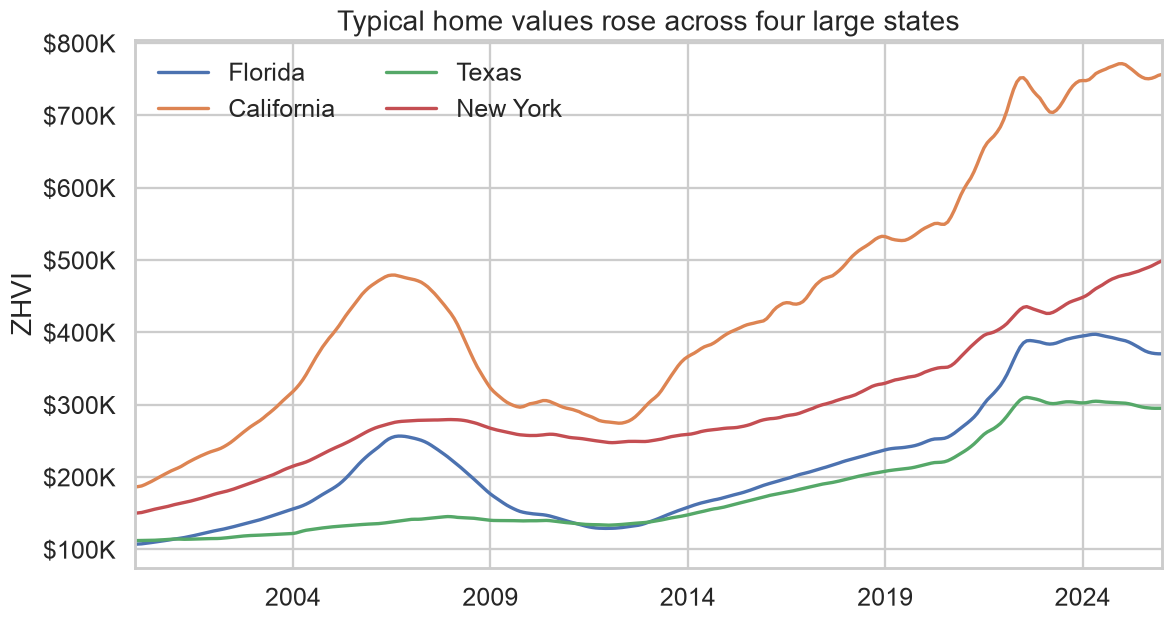

In [4]:
comparison_states = ["Florida", "California", "Texas", "New York"]
ax = raw[comparison_states].plot(linewidth=2.2, figsize=(11, 6))
ax.set_title("Typical home values rose across four large states")
ax.set_xlabel("")
ax.set_ylabel("ZHVI")
ax.yaxis.set_major_formatter(dollar_thousands)
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_state_home_value_trends.png", bbox_inches="tight")
plt.show()

California remained the highest-value state in this comparison. Florida and Texas started at similar levels, but Florida pulled away after 2020. The common direction across states also supports the earlier EDA finding that national forces influence housing markets.

## Florida growth accelerated, then cooled

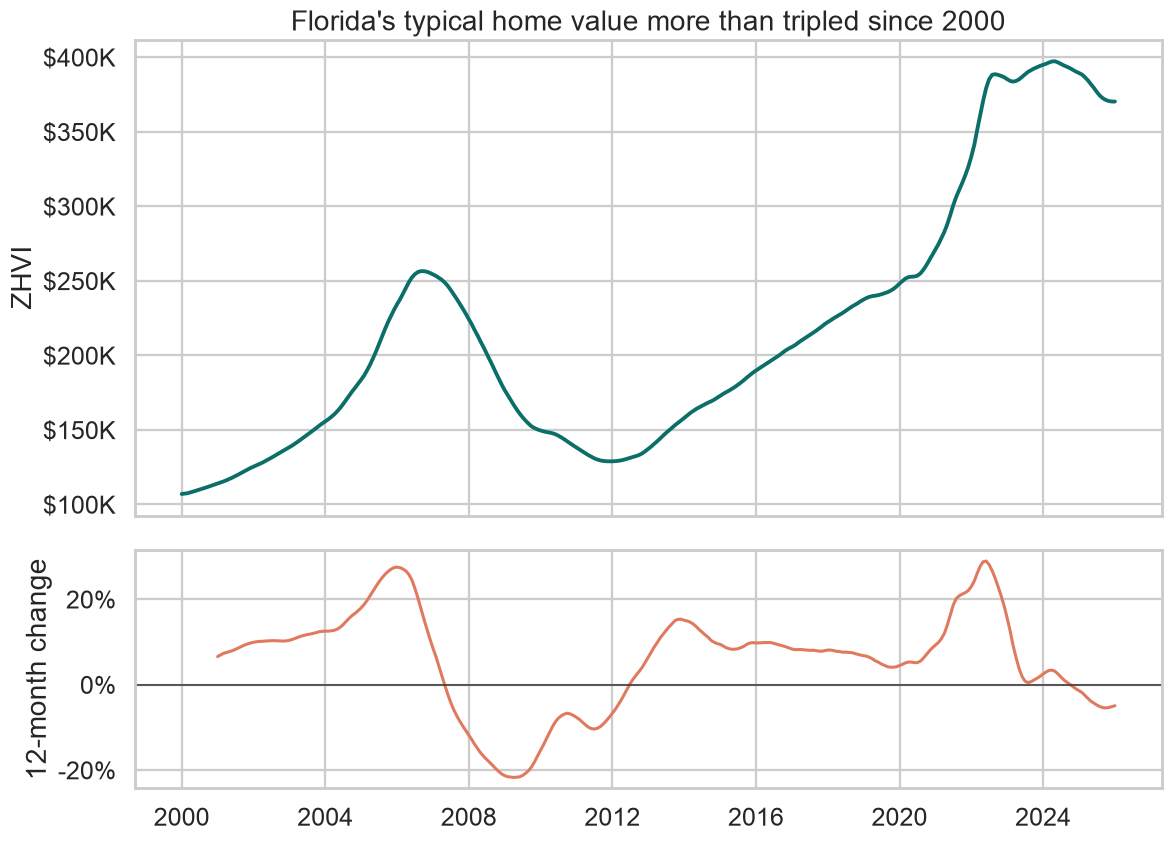

Peak 12-month growth: 29.0% in June 2022
Latest ZHVI: $370,112
Latest 12-month change: -4.9%


In [5]:
florida = raw["Florida"].dropna().rename("ZHVI")
florida_yoy = florida.pct_change(12) * 100

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(florida.index, florida, color="#0B6E69", linewidth=2.5)
axes[0].set_title("Florida's typical home value more than tripled since 2000")
axes[0].set_ylabel("ZHVI")
axes[0].yaxis.set_major_formatter(dollar_thousands)

axes[1].plot(florida_yoy.index, florida_yoy, color="#E07A5F", linewidth=2)
axes[1].axhline(0, color="#333333", linewidth=1)
axes[1].set_ylabel("12-month change")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
axes[1].set_xlabel("")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_florida_value_and_growth.png", bbox_inches="tight")
plt.show()

peak_date = florida_yoy.idxmax()
print(f"Peak 12-month growth: {florida_yoy.max():.1f}% in {peak_date:%B %Y}")
print(f"Latest ZHVI: ${florida.iloc[-1]:,.0f}")
print(f"Latest 12-month change: {florida_yoy.iloc[-1]:.1f}%")

## Latest cross-state snapshot

In [6]:
latest = raw.ffill().iloc[-1]
year_ago = raw.ffill().iloc[-13]
snapshot = pd.DataFrame({
    "latest_zhvi": latest,
    "one_year_change_pct": (latest / year_ago - 1) * 100,
}).dropna()

snapshot_table = snapshot.sort_values("latest_zhvi", ascending=False).head(10).copy()
snapshot_table["latest_zhvi"] = snapshot_table["latest_zhvi"].map(lambda x: f"${x:,.0f}")
snapshot_table["one_year_change_pct"] = snapshot_table["one_year_change_pct"].map(lambda x: f"{x:.1f}%")
snapshot_table

,latest_zhvi,one_year_change_pct
Hawaii,"$820,224",-1.9%
California,"$756,323",-1.9%
Massachusetts,"$638,534",1.6%
Washington,"$585,669",-0.5%
the District of Columbia,"$571,760",-3.0%
New Jersey,"$558,805",3.2%
Colorado,"$529,284",-2.5%
Utah,"$527,752",2.0%
New York,"$498,438",4.2%
New Hampshire,"$492,203",2.7%


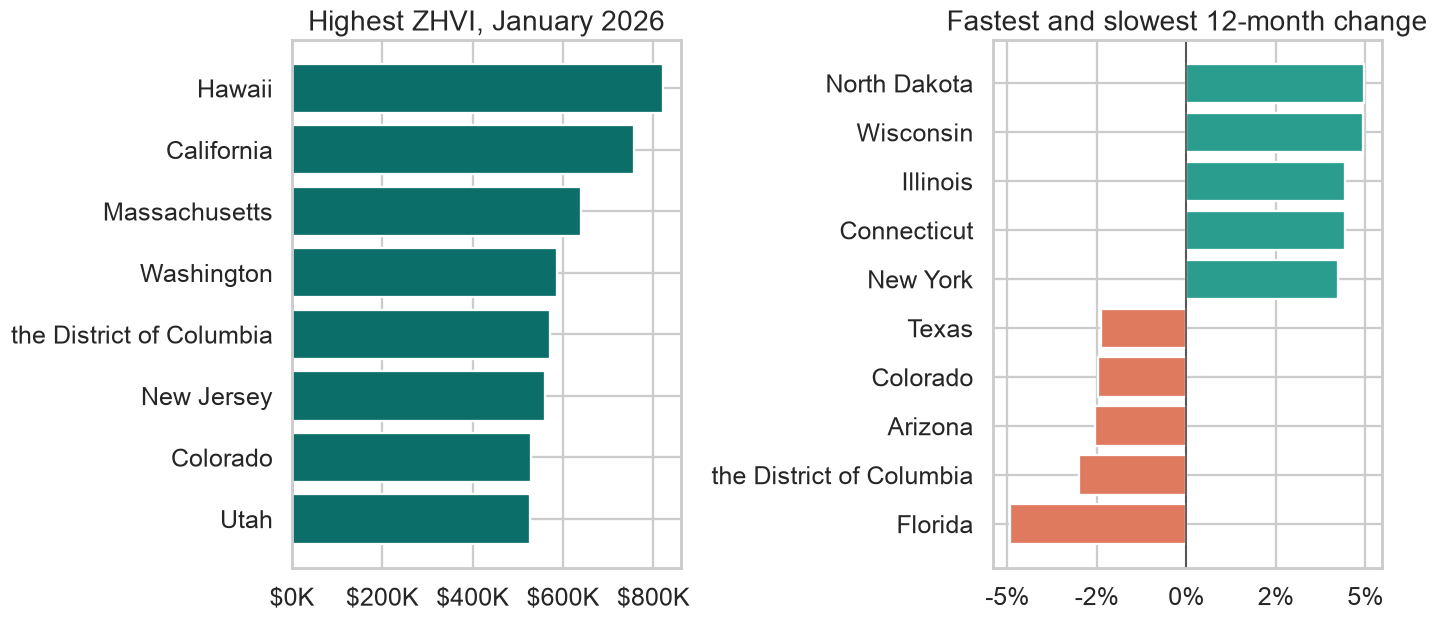

In [7]:
growth_display = snapshot.sort_values("one_year_change_pct", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

top = snapshot.nlargest(8, "latest_zhvi").sort_values("latest_zhvi")
axes[0].barh(top.index, top["latest_zhvi"], color="#0B6E69")
axes[0].set_title("Highest ZHVI, January 2026")
axes[0].xaxis.set_major_formatter(dollar_thousands)
axes[0].set_xlabel("")

growth = pd.concat([growth_display.head(5), growth_display.tail(5)]).sort_values("one_year_change_pct")
colors = np.where(growth["one_year_change_pct"] >= 0, "#2A9D8F", "#E07A5F")
axes[1].barh(growth.index, growth["one_year_change_pct"], color=colors)
axes[1].axvline(0, color="#333333", linewidth=1)
axes[1].set_title("Fastest and slowest 12-month change")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
axes[1].set_xlabel("")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_latest_state_snapshot.png", bbox_inches="tight")
plt.show()

## EDA conclusion

The file is suitable for a Florida forecasting exercise: it contains 313 consecutive monthly Florida observations and no missing Florida values. The sharp post-2020 rise and later cooling create a meaningful test for models. The cross-state view provides context, but ZHVI alone cannot establish whether a market is undervalued. Rental income, affordability, inventory, migration, and financing costs would be needed for that investment question.